# Lab 1 – Data Preparation (Adult dataset)

## 1. Business Understanding

The Adult dataset comes from the 1994 US census. It contains data about around 48,000 people
and their details (age, education, job, marital status, hours per week...) and if they earn
more or less than 50K per year.

Our goal is to predict, based on these features, if a person earns more or less than 50K.
So it's a binary classification problem.

This kind of model can be useful for a bank, to have an idea of a client's income before
giving him a loan or a credit card. It can also be used in marketing to target ads depending
on people's income.

We should be careful because the data has sensitive columns like sex and race. For example, in 1994 women earned less on average, so the model could learn to predict lower income just because a person is a woman, which would be unfair.

In this lab we will explore the data, clean it, try to find groups of people with clustering,
and then train classification models to predict the income.

The adult.names file reports old results from 1996: the best models reached about 84–86% accuracy. We will use this as a reference to compare our models.

## 2. Data Understanding


In [ ]:
import pandas as pd

columns = ["age", "workclass", "fnlwgt", "education", "education-num",
           "marital-status", "occupation", "relationship", "race", "sex",
           "capital-gain", "capital-loss", "hours-per-week", "native-country",
           "income"]

df = pd.read_csv("adult.data", header=None, names=columns, skipinitialspace=True)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
test = pd.read_csv("adult.test", header=None, names=columns,
                   skipinitialspace=True, skiprows=1)
test["income"].value_counts(normalize=True)

,proportion
income,
<=50K.,0.763774
>50K.,0.236226


The file has no column names, so we added them from adult.names. There is also a space after each comma, so we used skipinitialspace=True.

In [ ]:
df.shape

(32561, 15)

32561 rows and 15 columns, same as in adult.names.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


6 numeric columns and 9 categorical ones (including the target income). info() shows no missing values, but adult.names says the unknown values were replaced by "?", so they are hidden.

In [ ]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


capital-gain is 0 for at least 75% of people but the max is 99999, which looks like a special value, not a real amount. hours-per-week goes from 1 to 99, most people work 40 hours. fnlwgt is a census weight, it does not describe the person.

In [ ]:
(df == "?").sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


The missing values are in 3 columns: workclass (1836), occupation (1843) and native-country (583).

In [ ]:
missing_wc = df[df["workclass"] == "?"]
(missing_wc["occupation"] == "?").sum()

np.int64(1836)

The missing values in workclass and occupation are linked: all 1836 people with workclass = "?" also have occupation = "?".


In [ ]:
df[(df["occupation"] == "?") & (df["workclass"] != "?")]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
5361,18,Never-worked,206359,10th,6,Never-married,?,Own-child,White,Male,0,0,40,United-States,<=50K
10845,23,Never-worked,188535,7th-8th,4,Divorced,?,Not-in-family,White,Male,0,0,35,United-States,<=50K
14772,17,Never-worked,237272,10th,6,Never-married,?,Own-child,White,Male,0,0,30,United-States,<=50K
20337,18,Never-worked,157131,11th,7,Never-married,?,Own-child,White,Female,0,0,10,United-States,<=50K
23232,20,Never-worked,462294,Some-college,10,Never-married,?,Own-child,Black,Male,0,0,40,United-States,<=50K
32304,30,Never-worked,176673,HS-grad,9,Married-civ-spouse,?,Wife,Black,Female,0,0,40,United-States,<=50K
32314,18,Never-worked,153663,Some-college,10,Never-married,?,Own-child,White,Male,0,0,4,United-States,<=50K


The 7 other people with occupation = "?" have workclass = "Never-worked", which is logical. But they still work 4 to 40 hours per week, which is contradictory.

In [ ]:
missing_wc["age"].describe()

,age
count,1836.000000
mean,40.960240
std,20.334587
min,17.000000
25%,21.000000
50%,35.000000
75%,61.000000
max,90.000000


People with missing job info are often very young (25% are 21 or younger) or older (25% are 61 or older). They are probably students and retired people, so the missing values are not random

In [ ]:
pd.crosstab(df["education"], df["education-num"])

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,933,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1175,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,433,0,0,0,0,0,0,0,0
1st-4th,0,168,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,333,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,646,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,514,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1067,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,1382,0,0,0,0,0


In [ ]:
df["income"].value_counts(normalize=True)

,proportion
income,
<=50K,0.75919
>50K,0.24081


 We also noticed that education and education-num contain the same information, and that the target is imbalanced (about 76% earn <=50K and 24% earn >50K).

## 3. Data Exploration

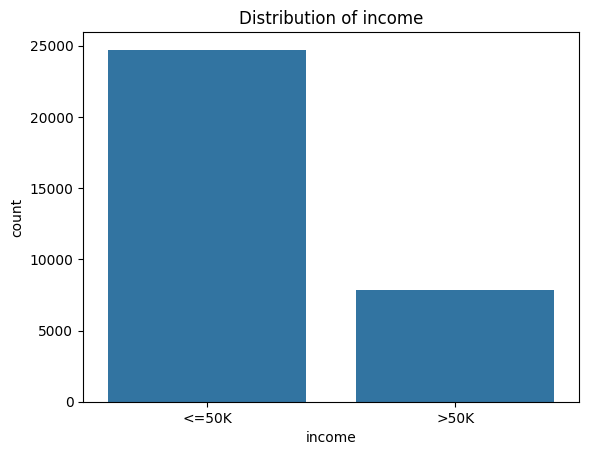

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="income", data=df)
plt.title("Distribution of income")
plt.show()

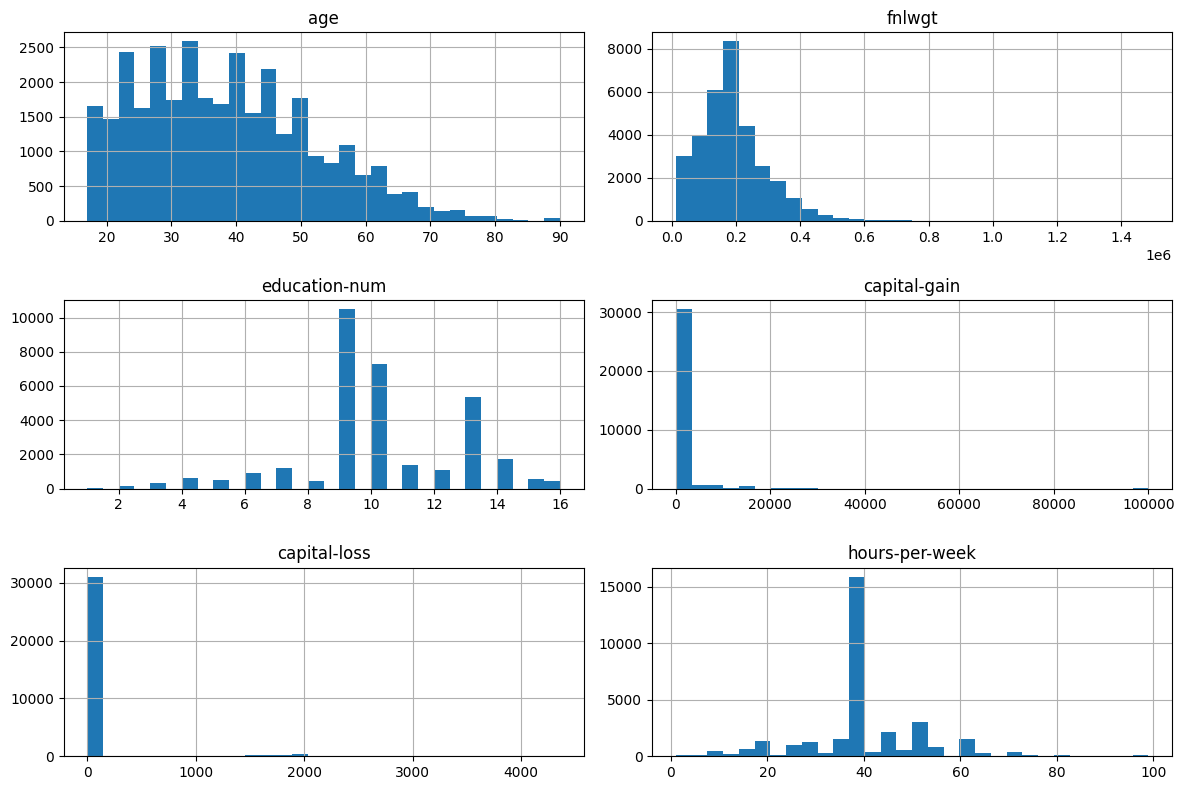

In [ ]:
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

fnlwgt is right-skewed with very big values (up to about 1.4 million) compared to the other columns. Since it's a census weight and not a feature of the person, and its big values could dominate distance-based models like K-Means and KNN, we plan to drop it.

age is between 17 and 90, most people are between 20 and 50, then fewer older people (slightly right-skewed). Nothing strange, the values make sense.

education-num has 3 big peaks: 9 (HS-grad), 10 (Some-college) and 13 (Bachelors). Most people stopped after high school, some college or a bachelor.

capital-gain and capital-loss are 0 for almost everyone, so they are very skewed. In capital-gain there is a small bar alone at 100000 (the 99999 values). We will need to treat these columns (for example a log transformation or a yes/no column "has capital gain").

hours-per-week has a big peak at 40 hours (full-time job). Some people work less than 20 hours (part-time) and a few work close to 99 hours, which we will check with a boxplot.

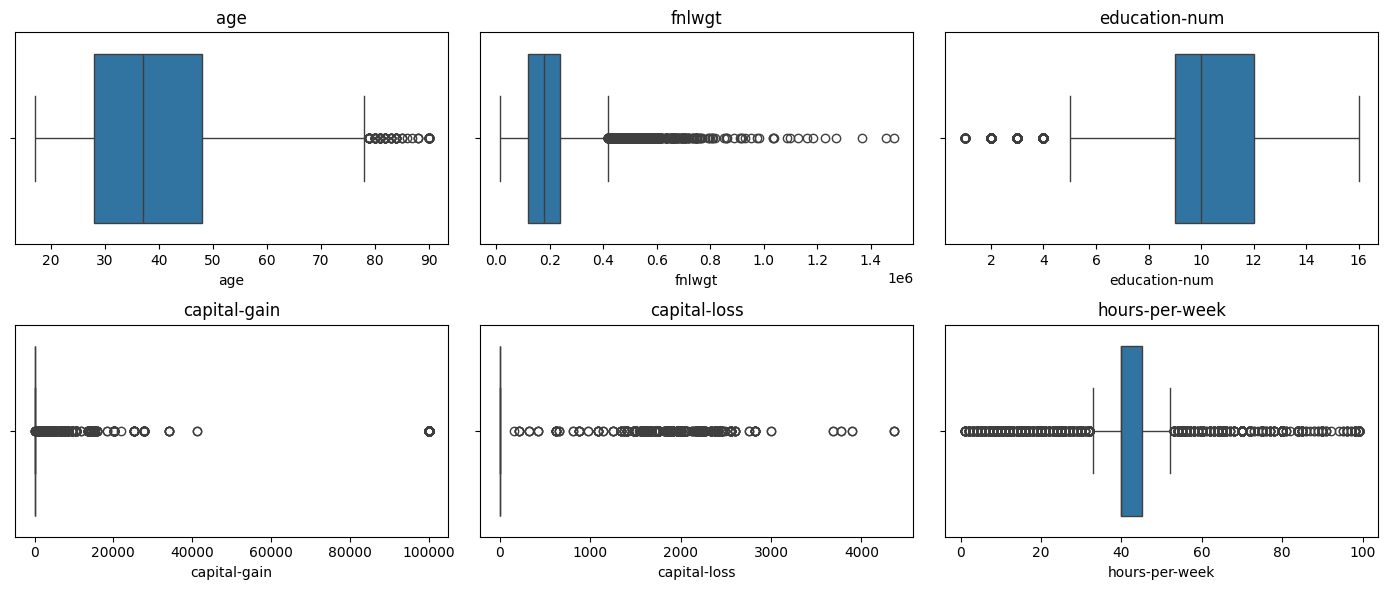

In [ ]:
num_cols = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]

plt.figure(figsize=(14, 6))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
print((df["capital-gain"] == 99999).sum())
print(df[df["capital-gain"] == 99999]["income"].value_counts())
print((df["age"] == 90).sum(), (df["age"] == 89).sum())
print((df["hours-per-week"] == 99).sum(), (df["hours-per-week"] == 98).sum())
print((df["capital-gain"] > 0).mean(), (df["capital-loss"] > 0).mean())

159
income
>50K    159
Name: count, dtype: int64
43 0
85 11
0.08328982525106723 0.0466509013850926


The boxplots show a lot of outliers, but most of them are real values and not errors:

age: the outliers are people older than 78. They are rare but normal. We found 43 people at exactly 90 and nobody at 89, so 90 probably means "90 or older".
education-num: the outliers are people with very little education (1 to 4). Rare but real.
hours-per-week: the box is very small (40 to 45) because a lot of people work exactly 40 hours, so part-time and overtime workers are seen as outliers. There are 85 people at exactly 99 hours, which looks like a maximum limit ("99 or more").
capital-gain and capital-loss: more than 75% of people have 0, so the box is just a line at 0 and every value above 0 becomes an outlier. These are just the people who have investments (about 8% for gain and 5% for loss). The only suspicious value is 99999 in capital-gain: 159 people have it and they all earn >50K, so it looks like a special code.
fnlwgt: a lot of outliers because of the long tail, but we plan to drop this column.

So we decided not to delete the outliers, because we would lose real people (for example the people with capital gain, who are often the ones earning >50K).

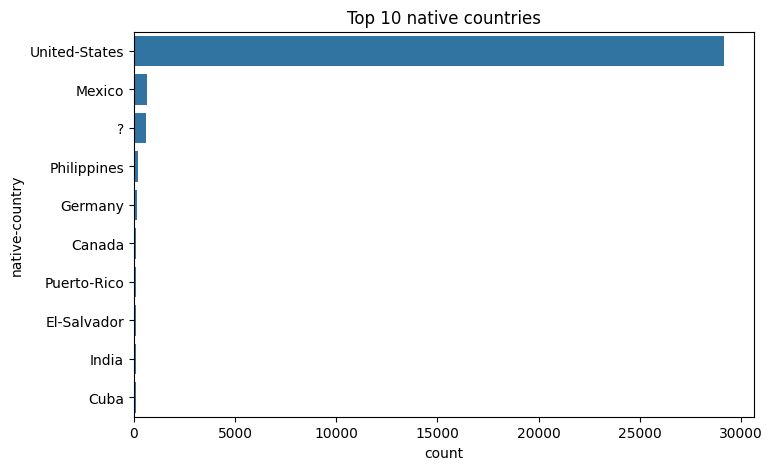

In [ ]:
top_countries = df["native-country"].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 native countries")
plt.xlabel("count")
plt.show()

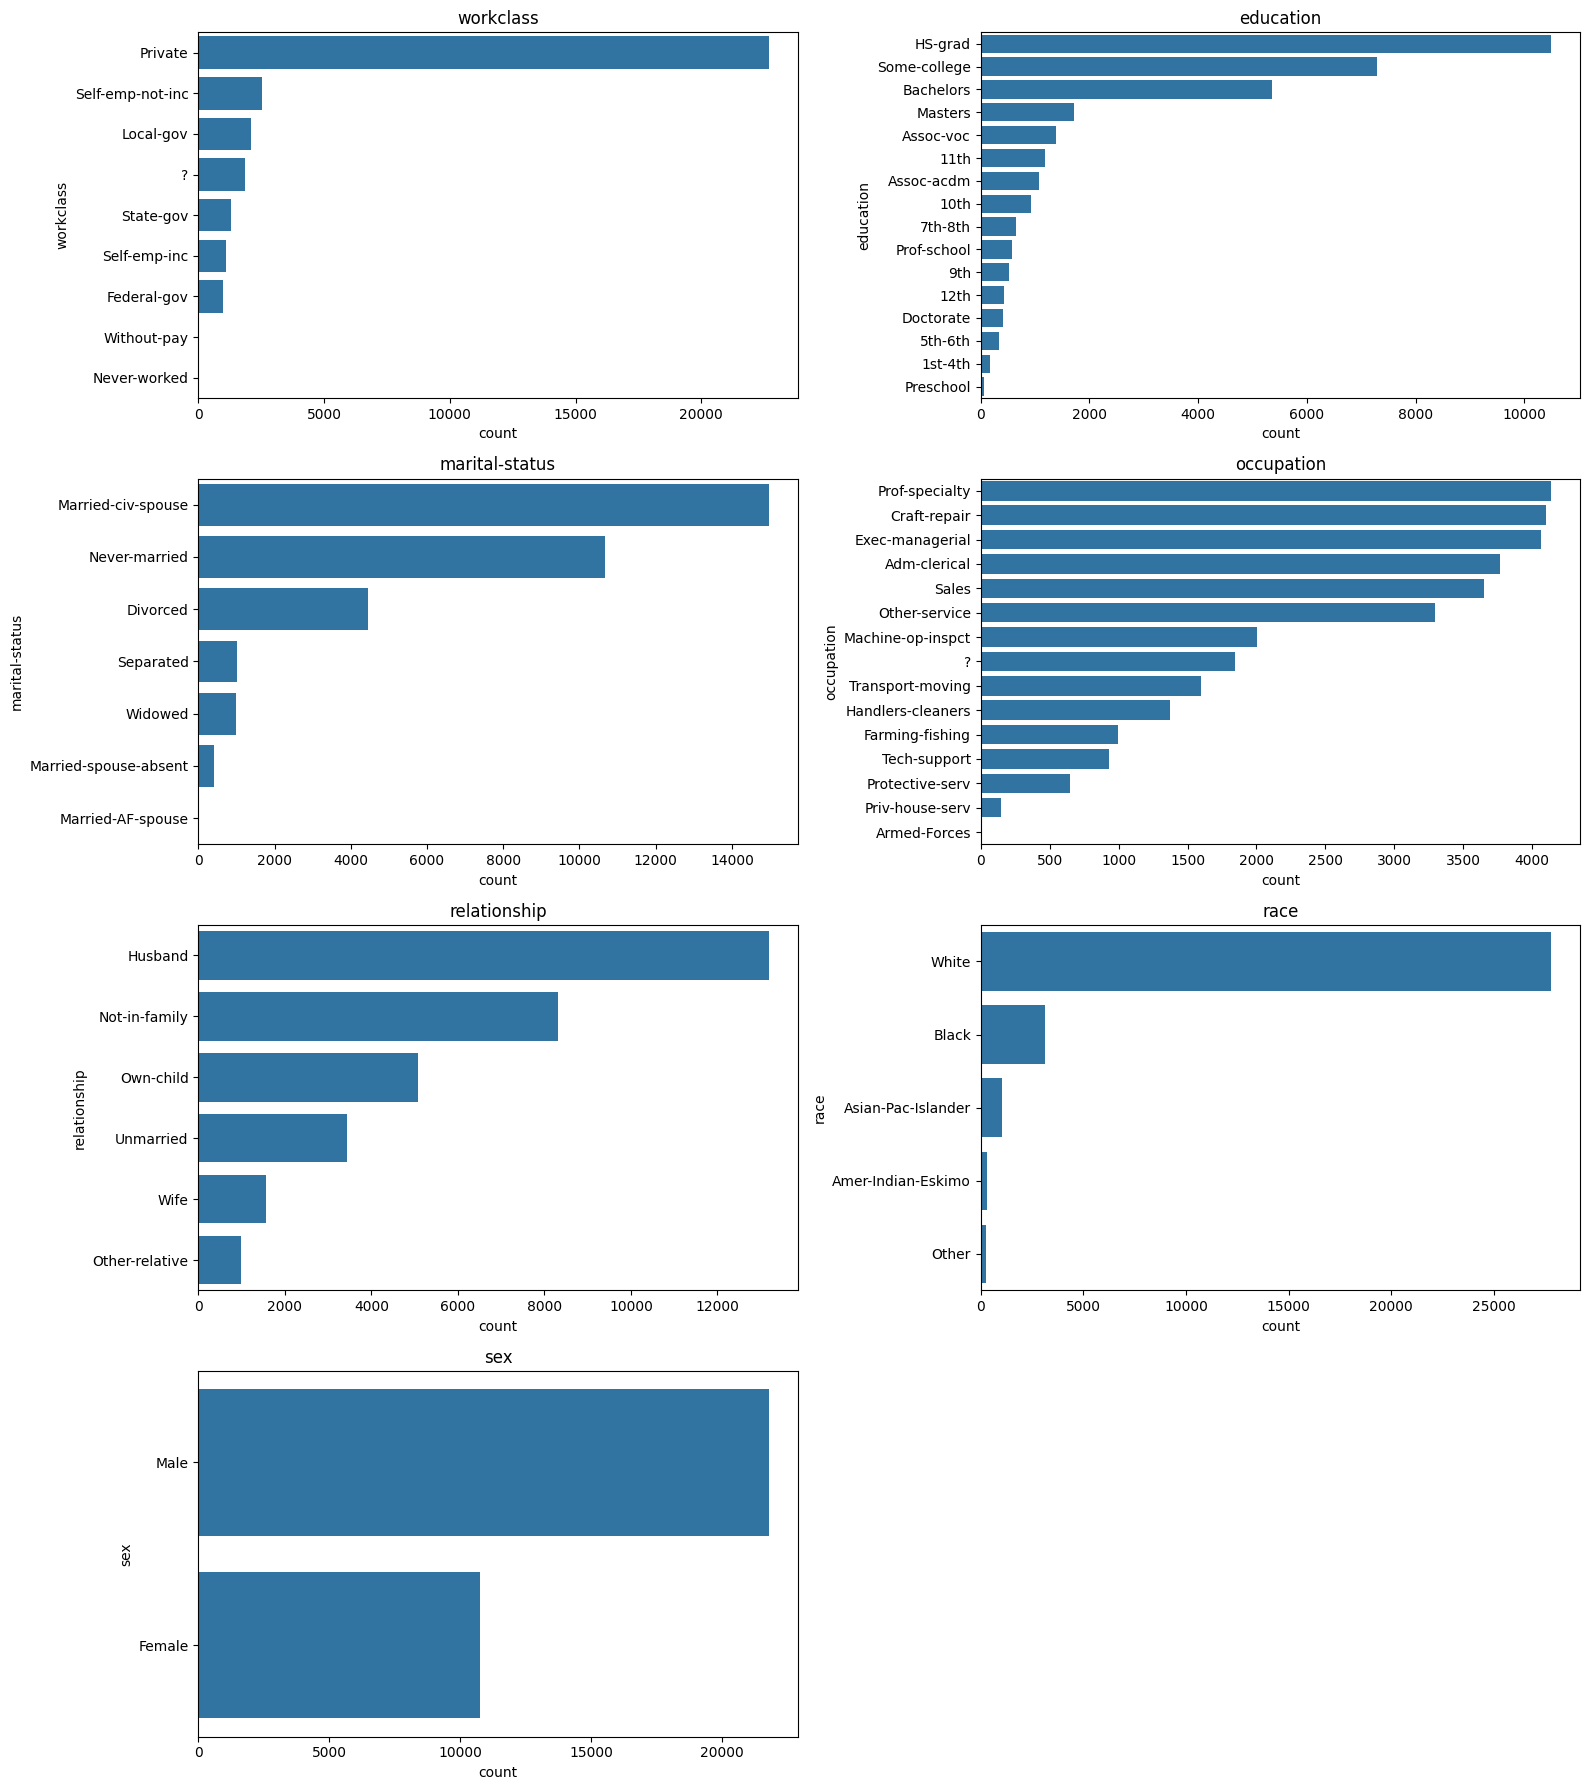

In [ ]:
cat_cols = ["workclass", "education", "marital-status", "occupation",
            "relationship", "race", "sex"]

plt.figure(figsize=(16, 18))
for i, col in enumerate(cat_cols):
    plt.subplot(4, 2, i + 1)
    sns.countplot(y=df[col], order=df[col].value_counts().index)
    plt.title(col)
plt.tight_layout()
plt.show()

workclass: most people work in the private sector (about 70%). The "?" category is visible (1836 people). Without-pay (14) and Never-worked (7) are almost empty.
education: most people are HS-grad, Some-college or Bachelors. Some categories are very small, like Preschool (51) or 1st-4th (168).
marital-status: most people are Married-civ-spouse or Never-married. Married-AF-spouse has only 23 people.
occupation: the jobs are more balanced, the biggest ones are Prof-specialty, Craft-repair and Exec-managerial (about 4000 each). "?" appears here too (1843). Armed-Forces has only 9 people.
relationship: Husband is the biggest category, much more than Wife. This matches the sex chart.
race: the dataset is very unbalanced, about 85% are White and 10% Black. The other groups are very small.
sex: about 67% men and 33% women, so women are under-represented.
native-country: about 90% are from the United States, the second country is Mexico with only 2%. Most countries have very few people.

Some categories have very few people, so the models will not learn much from them. We could group the small categories together later (for example all countries except the US into "Other").

### Relationships with the target

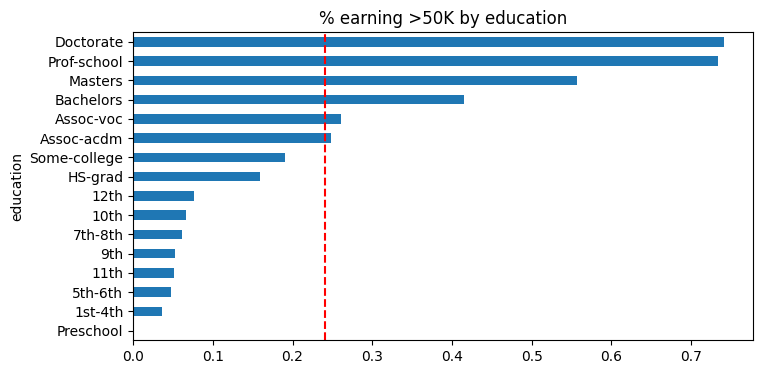

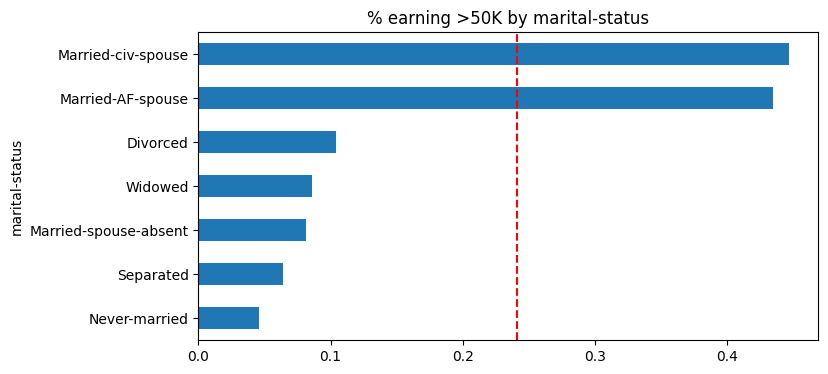

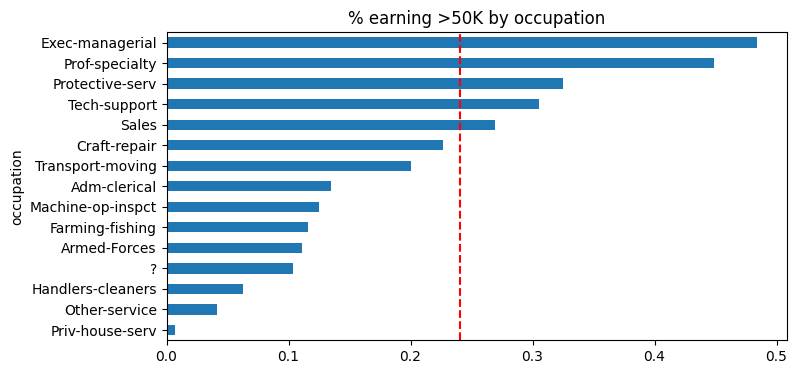

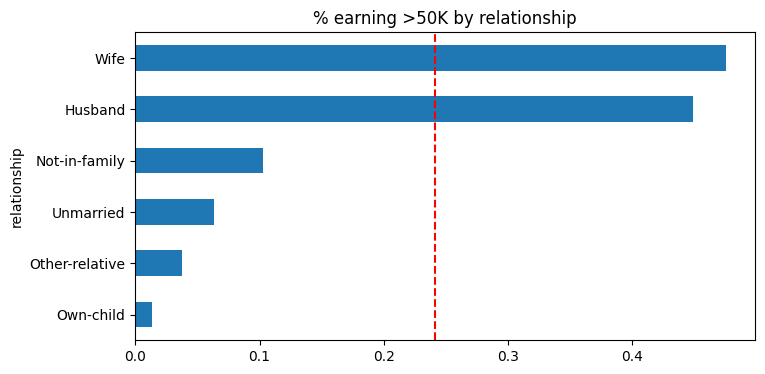

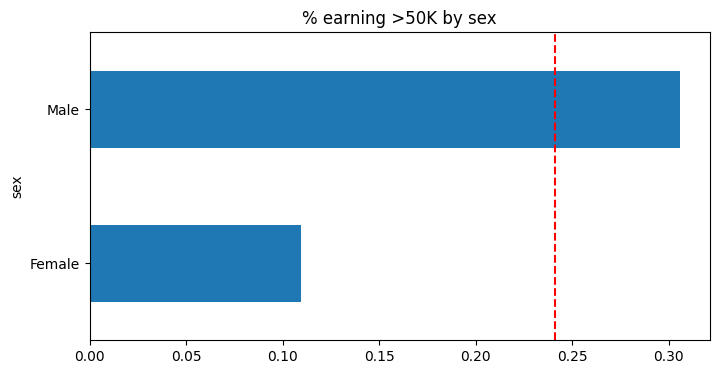

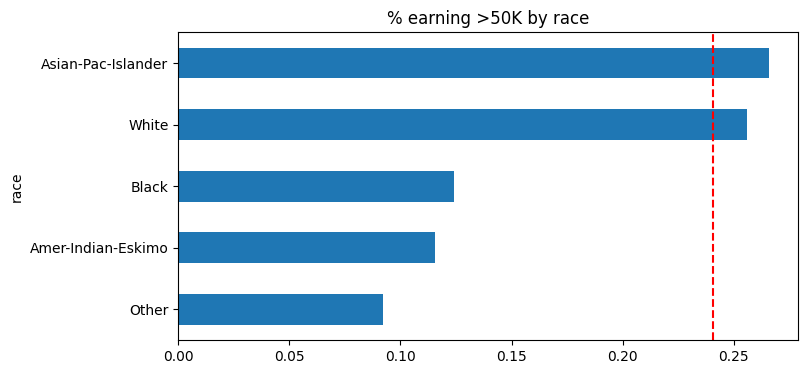

In [ ]:
df["high_income"] = (df["income"] == ">50K").astype(int)

for col in ["education", "marital-status", "occupation", "relationship", "sex", "race"]:
    rate = df.groupby(col)["high_income"].mean().sort_values()
    rate.plot(kind="barh", figsize=(8, 4), title="% earning >50K by " + col)
    plt.axvline(df["high_income"].mean(), color="red", linestyle="--")
    plt.show()

The red line is the average: 24% of all people earn >50K.

education: the higher the diploma, the more people earn >50K. About 74% for Doctorate, 41% for Bachelors and 16% for HS-grad. It looks like the strongest link with income.
marital-status: married people earn much more (45% for Married-civ-spouse) than never-married people (5%). This is partly because never-married people are often young. Married-AF-spouse is also high but it has only 23 people, so we can't trust it.
occupation: Exec-managerial (48%) and Prof-specialty (45%) are the richest jobs. Priv-house-serv (1%) and Other-service (4%) are the poorest. People with occupation "?" are also low (10%).
relationship: Wife (48%) and Husband (45%) are far above the average, Own-child is almost 0% (young people living with their parents).
sex: men earn >50K much more often than women (31% vs 11%). Wives earn as much as husbands, but only 15% of women are wives while 60% of men are husbands, so overall men are richer.
race: White (26%) and Asian-Pac-Islander (27%) are above the average, Black and Amer-Indian-Eskimo are around 12%.

Education, marital-status, relationship and occupation look like the most useful features to predict income.

In [ ]:
pd.crosstab(df["sex"], df["relationship"])

relationship,Husband,Not-in-family,Other-relative,Own-child,Unmarried,Wife
sex,,,,,,
Female,1,3875,430,2245,2654,1566
Male,13192,4430,551,2823,792,2


1 woman is labeled "Husband" and 2 men are labeled "Wife", which is impossible. These are errors in the data. Since it's only 3 rows, we can delete them in the cleaning step. We can also see that there are 13192 husbands but only 1566 wives.

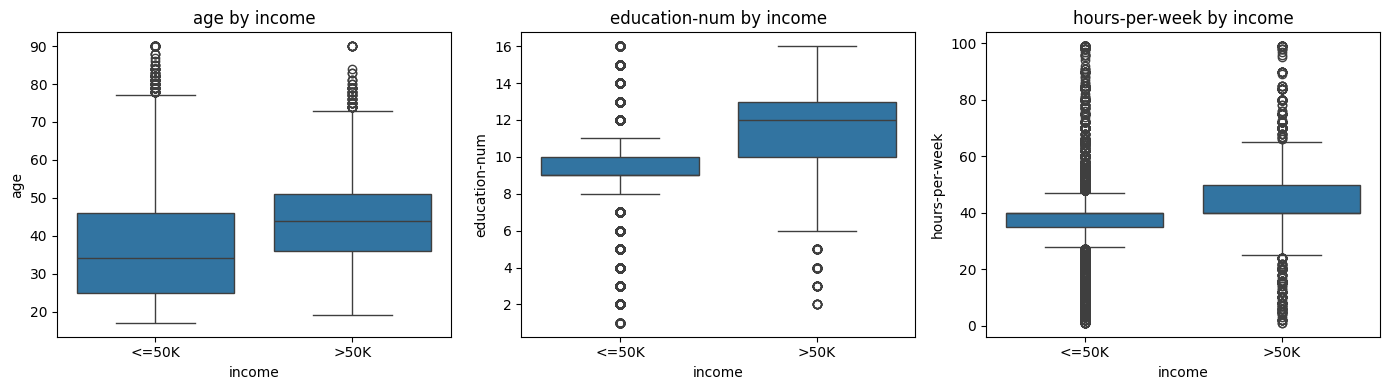

In [ ]:
plt.figure(figsize=(14, 4))
for i, col in enumerate(["age", "education-num", "hours-per-week"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x="income", y=col, data=df)
    plt.title(col + " by income")
plt.tight_layout()
plt.show()

We compared age, education-num and hours-per-week between the two income groups (capital-gain and capital-loss are not shown because their box is just a line at 0).

People earning >50K are older: median about 44 years against 34.
They are more educated: median education-num of 12 against 9. This is the biggest difference.
They work more hours: most of them work between 40 and 50 hours, while people earning <=50K mostly work between 35 and 40.
So these 3 columns are useful to predict income.

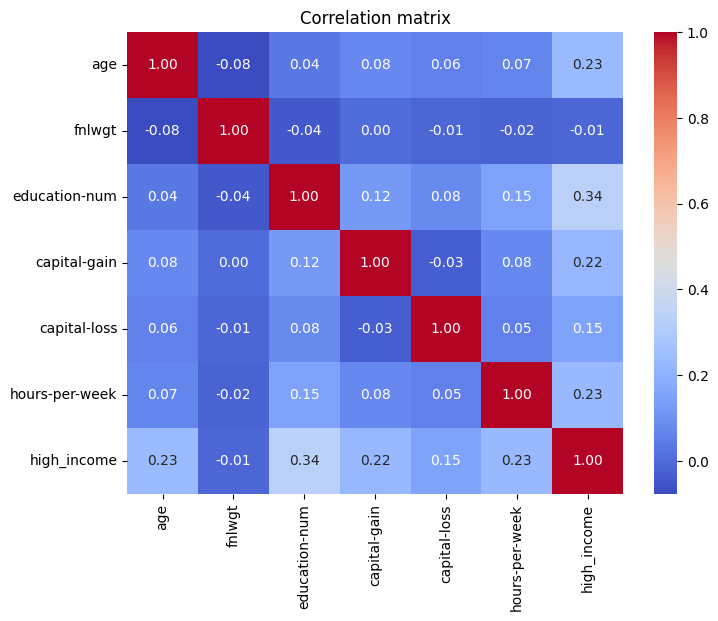

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["high_income"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

education-num has the strongest correlation with income (0.34), then age and hours-per-week (0.23) and capital-gain (0.22). fnlwgt has a correlation of -0.01 with income, so it has no link with it, which confirms our decision to drop it. The numeric columns are not strongly correlated with each other (all below 0.2), so there is no redundant numeric column. Correlation only shows linear links, so for very skewed columns like capital-gain, it may underestimate their importance.

## 4. Data Preparation

### 4.1 Data Cleaning

In [ ]:
df_clean = df.drop(columns=["high_income"]).copy()

print("Duplicates:", df_clean.duplicated().sum())

Duplicates: 24


In [ ]:
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

(32537, 15)


We found 24 duplicate rows. Since they are identical on all 15 columns, including fnlwgt which is a very precise number, they are probably the same person recorded twice, so we deleted them. We checked duplicates before dropping fnlwgt, otherwise different people with the same profile would look like duplicates.

In [ ]:
errors = ((df_clean["sex"] == "Female") & (df_clean["relationship"] == "Husband")) | \
         ((df_clean["sex"] == "Male") & (df_clean["relationship"] == "Wife"))

print("Impossible rows:", errors.sum())
df_clean = df_clean[~errors]
print(df_clean.shape)

Impossible rows: 3
(32534, 15)


1 woman is labeled "Husband" and 2 men are labeled "Wife", which is impossible. We can't know if the error is in sex or in relationship, so we deleted these 3 rows instead of guessing. It's only 3 rows, so it has no real impact on the data.

In [ ]:
pd.crosstab(df["marital-status"], df["relationship"])

relationship,Husband,Not-in-family,Other-relative,Own-child,Unmarried,Wife
marital-status,,,,,,
Divorced,0,2404,110,328,1601,0
Married-AF-spouse,9,0,1,1,0,12
Married-civ-spouse,13184,17,124,95,0,1556
Married-spouse-absent,0,211,32,45,130,0
Never-married,0,4706,611,4485,881,0
Separated,0,420,55,99,451,0
Widowed,0,547,48,15,383,0


We also checked if marital-status and relationship are consistent. Husband and Wife only appear with married people, and Unmarried never appears with Married-civ-spouse, so there is no contradiction. Some married people are Own-child or Other-relative, but this is possible because relationship describes the role in the household (for example a married couple living with the husband's parents).

In [ ]:
print("Never-worked:", (df_clean["workclass"] == "Never-worked").sum())
df_clean = df_clean[df_clean["workclass"] != "Never-worked"]
print(df_clean.shape)

Never-worked: 7
(32527, 15)


The 7 people with workclass "Never-worked" have occupation "?" but still work 4 to 40 hours per week, which is contradictory. We deleted them because we can't trust these rows, and 7 people is too few for a model to learn anything from this category.

In [ ]:
df_clean["workclass"] = df_clean["workclass"].replace("?", "Unknown")
df_clean["occupation"] = df_clean["occupation"].replace("?", "Unknown")

mode_country = df_clean["native-country"].mode()[0]
df_clean["native-country"] = df_clean["native-country"].replace("?", mode_country)

print("Mode of native-country:", mode_country)
print((df_clean == "?").sum().sum())

Mode of native-country: United-States
0


For workclass and occupation, we replaced "?" by a new category "Unknown". We didn't delete these rows because the missing values are not random (a lot of young and old people), so deleting them would remove a part of the population. We didn't use the mode either, because it would give a job to people who probably don't work (students, retired). Also, being "Unknown" is useful information: only about 10% of these people earn >50K.
For native-country, only 1.8% of the values are missing and about 90% of people are from the United States, so we replaced "?" by the mode (United-States).

### 4.2 Data Transformation

In [ ]:
df_clean = df_clean.drop(columns=["fnlwgt", "education"])
print(df_clean.shape)
print(df_clean.columns.tolist())

(32527, 13)
['age', 'workclass', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


We dropped fnlwgt because it is a census weight that does not describe the person, and its correlation with income is -0.01. We dropped education because it contains the same information as education-num. We kept education-num because it is already numeric and it keeps the order of the levels.

In [ ]:
df_clean["has_capital_gain"] = (df_clean["capital-gain"] > 0).astype(int)
df_clean["has_capital_loss"] = (df_clean["capital-loss"] > 0).astype(int)

married = ["Married-civ-spouse", "Married-AF-spouse"]
df_clean["lives_with_spouse"] = df_clean["marital-status"].isin(married).astype(int)

df_clean[["capital-gain", "has_capital_gain", "marital-status", "lives_with_spouse"]].head(10)

,capital-gain,has_capital_gain,marital-status,lives_with_spouse
0,2174,1,Never-married,0
1,0,0,Married-civ-spouse,1
2,0,0,Divorced,0
3,0,0,Married-civ-spouse,1
4,0,0,Married-civ-spouse,1
5,0,0,Married-civ-spouse,1
6,0,0,Married-spouse-absent,0
7,0,0,Married-civ-spouse,1
8,14084,1,Never-married,0
9,5178,1,Married-civ-spouse,1


We created 3 new columns based on what we found in the exploration:

has_capital_gain and has_capital_loss: 1 if the value is above 0, otherwise 0. Most people have 0, and having a capital gain is a strong sign of high income (62% earn >50K against 21%).
lives_with_spouse: 1 (yes) for Married-civ-spouse and Married-AF-spouse, 0 (no) for everyone else. These two groups have about 45% of >50K, while all the others have 5-10%. Married-spouse-absent and Separated are married but don't live with their spouse, so they get 0.

In [ ]:
df_clean = df_clean.drop(columns=["marital-status"])

In [ ]:
import numpy as np

df_clean["native-country"] = np.where(df_clean["native-country"] == "United-States",
                                      "United-States", "Other")

df_clean["workclass"] = df_clean["workclass"].replace("Without-pay", "Unknown")
df_clean["occupation"] = df_clean["occupation"].replace("Armed-Forces", "Protective-serv")



In [ ]:
print(df_clean["native-country"].value_counts())
print(df_clean["workclass"].value_counts())
print(df_clean["occupation"].value_counts())

native-country
United-States    29725
Other             2802
Name: count, dtype: int64
workclass
Private             22670
Self-emp-not-inc     2540
Local-gov            2093
Unknown              1850
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Name: count, dtype: int64
occupation
Prof-specialty       4136
Craft-repair         4094
Exec-managerial      4064
Adm-clerical         3768
Sales                3648
Other-service        3291
Machine-op-inspct    2000
Unknown              1836
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       658
Priv-house-serv       147
Name: count, dtype: int64


native-country has 41 countries but 90% of people are from the US and most countries have very few people, so we grouped them into "United-States" and "Other". We also merged the tiny categories: Without-pay (14 people) into Unknown, and Armed-Forces (9 people) into Protective-serv, the closest job. A model can't learn from so few people, and it also avoids creating many almost empty columns during the encoding.

In [ ]:
df_clean["capital-gain"] = np.log1p(df_clean["capital-gain"])
df_clean["capital-loss"] = np.log1p(df_clean["capital-loss"])

df_clean[["capital-gain", "capital-loss"]].describe()

,capital-gain,capital-loss
count,32527.000000,32527.000000
mean,0.735389,0.350671
std,2.455905,1.585368
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,11.512925,8.379539


capital-gain and capital-loss are very skewed with huge values (up to 99999). We applied log(1 + x): 0 stays 0 and big values are squeezed (99999 becomes about 11.5). This reduces the influence of the extreme values on models like K-Means and logistic regression. We didn't apply it to age and hours-per-week because they are not very skewed

In [ ]:
df_clean["income"] = (df_clean["income"] == ">50K").astype(int)

cat_cols = ["workclass", "occupation", "relationship", "race", "sex", "native-country"]
df_final = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)

print(df_final.shape)
df_final.head()

(32527, 39)


,age,education-num,capital-gain,capital-loss,hours-per-week,income,has_capital_gain,has_capital_loss,lives_with_spouse,workclass_Local-gov,...,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_United-States
0,39,13,7.684784,0.0,40,0,1,0,0,0,...,0,0,0,0,0,0,0,1,1,1
1,50,13,0.000000,0.0,13,0,0,0,1,0,...,0,0,0,0,0,0,0,1,1,1
2,38,9,0.000000,0.0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,1
3,53,7,0.000000,0.0,40,0,0,0,1,0,...,0,0,0,0,0,1,0,0,1,1
4,28,13,0.000000,0.0,40,0,0,0,1,0,...,0,0,0,1,0,1,0,0,0,0


We encoded income as 1 (>50K) and 0 (<=50K). For the categorical columns we used one-hot encoding: each category becomes a 0/1 column. We didn't use label encoding (1, 2, 3...) because these categories have no order (for example "Sales" is not bigger than "Tech-support"), and numbers would make the model think there is one. We used drop_first=True to remove one redundant column per variable. The final dataset has 32527 rows and 39 columns.

In [ ]:
df_final.to_csv("adult_clean.csv", index=False)
print("Saved:", df_final.shape)

Saved: (32527, 39)


## 5. Clustering

Goal: find groups of people with similar socio-economic profiles, without using the income. A bank or a marketing company could use these groups to target different offers. We use K-Means, which puts people into K groups so that people in the same group are close to each other.

We used 6 features: age, education-num, hours-per-week, capital-gain, lives_with_spouse and sex_Male. We didn't use all 38 columns because K-Means works with distances, and the many one-hot columns (mostly 0) would add noise and make the groups hard to interpret. We don't use income: clustering is unsupervised, so we only use income after, to describe the groups.

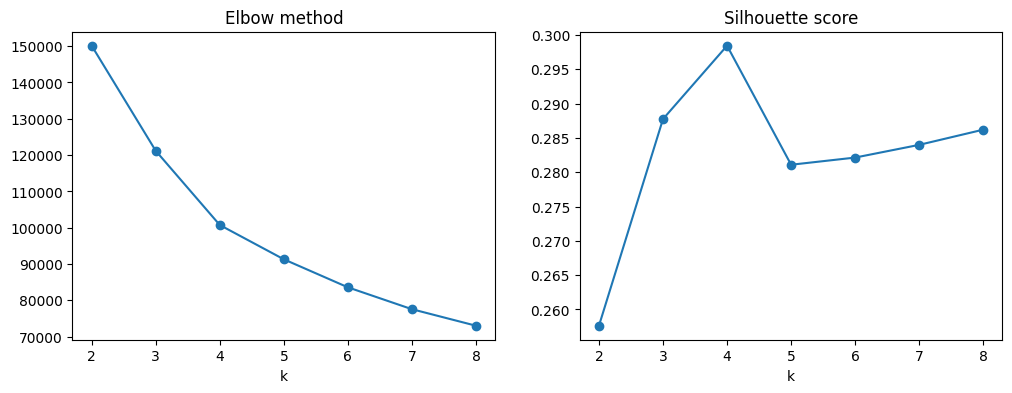

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = ["age", "education-num", "hours-per-week", "capital-gain",
                    "lives_with_spouse", "sex_Male"]
X_cluster = StandardScaler().fit_transform(df_final[cluster_features])

inertias = []
silhouettes = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 9), inertias, marker="o")
ax[0].set_title("Elbow method")
ax[0].set_xlabel("k")
ax[1].plot(range(2, 9), silhouettes, marker="o")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k")
plt.show()

We scaled the features with StandardScaler because K-Means uses distances: without scaling, age (up to 90) would dominate binary columns like lives_with_spouse (0 or 1).
To choose K, we used the elbow method: the inertia drops fast until k = 4, then much more slowly. The silhouette score is also the highest for k = 4 (about 0.30). So we chose 4 clusters. A silhouette of 0.30 means the groups are not perfectly separated, which is normal for real data about people.

In [ ]:
from sklearn.decomposition import PCA

all_cols = [c for c in df_final.columns if c not in ["income", "cluster"]]

options = {
    "All 38 columns": StandardScaler().fit_transform(df_final[all_cols]),
    "PCA (38 columns -> 5)": PCA(n_components=5, random_state=42).fit_transform(
                                 StandardScaler().fit_transform(df_final[all_cols])),
    "Our 6 features": StandardScaler().fit_transform(df_final[cluster_features]),
    "4 numeric only": StandardScaler().fit_transform(
                          df_final[["age", "education-num", "hours-per-week", "capital-gain"]])
}

for name, X_opt in options.items():
    for k in [2, 4]:
        labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_opt)
        score = silhouette_score(X_opt, labels, sample_size=5000, random_state=42)
        print(name, "| k =", k, "| silhouette =", round(score, 3))

All 38 columns | k = 2 | silhouette = 0.182
All 38 columns | k = 4 | silhouette = 0.088
PCA (38 columns -> 5) | k = 2 | silhouette = 0.477
PCA (38 columns -> 5) | k = 4 | silhouette = 0.304
Our 6 features | k = 2 | silhouette = 0.258
Our 6 features | k = 4 | silhouette = 0.298
4 numeric only | k = 2 | silhouette = 0.5
4 numeric only | k = 4 | silhouette = 0.304


We compared other choices. Using all 38 columns gives the worst silhouette (0.18 for k = 2, 0.09 for k = 4) because of the many one-hot columns. PCA (38 columns compressed into 5) and the 4 numeric columns alone give a higher silhouette with k = 2 (0.48 and 0.50), but K-Means then just separates people with and without capital gain, which is a trivial split that we already have in the column has_capital_gain. With k = 4, PCA, the 4 numeric columns and our 6 features all give almost the same silhouette (about 0.30). So we kept our 6 features with k = 4: same quality, but the groups are easier to interpret (PCA columns are mixtures of the original columns) and they include important information like marriage and sex. A silhouette of 0.30 is normal for data about people, because there are no clear borders between profiles.

In [ ]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df_final["cluster"] = kmeans.fit_predict(X_cluster)

print(df_final["cluster"].value_counts().sort_index())
df_final.groupby("cluster")[cluster_features + ["income"]].mean().round(2)

cluster
0    11933
1     2672
2    10022
3     7900
Name: count, dtype: int64


,age,education-num,hours-per-week,capital-gain,lives_with_spouse,sex_Male,income
cluster,,,,,,,
0,43.62,10.22,44.11,0.00,0.99,0.99,0.40
1,44.31,11.11,43.81,8.86,0.68,0.78,0.63
2,36.33,9.96,36.03,0.02,0.13,0.00,0.08
3,31.93,9.68,39.36,0.01,0.00,1.00,0.06


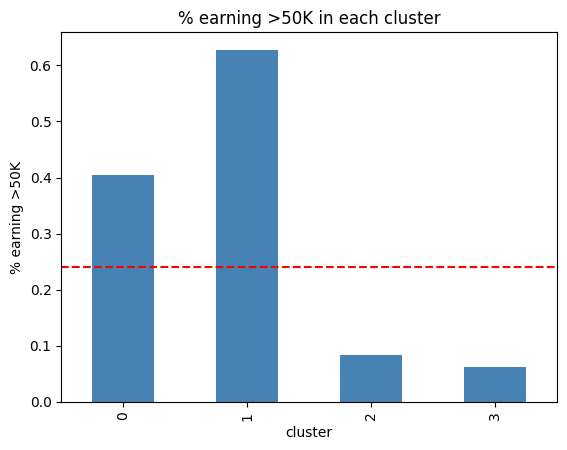

In [ ]:
df_final.groupby("cluster")["income"].mean().plot(kind="bar", color="steelblue")
plt.axhline(df_final["income"].mean(), color="red", linestyle="--")
plt.title("% earning >50K in each cluster")
plt.ylabel("% earning >50K")
plt.show()

We found 4 groups:

Cluster 0 (11933 people): married men, around 44 years old, working about 44 hours per week, with no capital gain. 40% earn >50K.

Cluster 1 (2672 people): people with capital gain (investors), around 44 years old, the most educated, mostly married men. 63% earn >50K, the richest group.

Cluster 2 (10022 people): women, mostly not living with a spouse, around 36 years old, working fewer hours (36 per week). Only 8% earn >50K.

Cluster 3 (7900 people): young single men, around 32 years old. Only 6% earn >50K.

Even without using the income, K-Means found groups with very different income levels (from 6% to 63%). This confirms what we saw in the exploration: being married, having a capital gain, age and education are strongly linked to income. A bank could for example target cluster 1 for investment products, and clusters 2 and 3 for basic accounts or small loans.

In [ ]:
df_final = df_final.drop(columns=["cluster"])

## 6. Classification

Goal: predict if a person earns more than 50K (income = 1) or not (income = 0), using all the features. We compare 5 models studied last year: Logistic Regression, KNN, Naive Bayes, Decision Tree and Random Forest. We didn't use SVM because it is very slow on more than 26000 rows. Since the classes are imbalanced, we evaluate the models with accuracy but also with precision, recall, F1-score and ROC-AUC.

In [ ]:
test = pd.read_csv("adult.test", header=None, names=columns,
                   skipinitialspace=True, skiprows=1)
test_clean = test.copy()

test_clean["income"] = test_clean["income"].str.replace(".", "", regex=False)
test_clean = test_clean[test_clean["workclass"] != "Never-worked"]

test_clean["workclass"] = test_clean["workclass"].replace(["?", "Without-pay"], "Unknown")
test_clean["occupation"] = test_clean["occupation"].replace("?", "Unknown").replace("Armed-Forces", "Protective-serv")
test_clean["native-country"] = test_clean["native-country"].replace("?", mode_country)
test_clean["native-country"] = np.where(test_clean["native-country"] == "United-States",
                                        "United-States", "Other")

test_clean = test_clean.drop(columns=["fnlwgt", "education"])
test_clean["has_capital_gain"] = (test_clean["capital-gain"] > 0).astype(int)
test_clean["has_capital_loss"] = (test_clean["capital-loss"] > 0).astype(int)
test_clean["lives_with_spouse"] = test_clean["marital-status"].isin(married).astype(int)
test_clean = test_clean.drop(columns=["marital-status"])

test_clean["capital-gain"] = np.log1p(test_clean["capital-gain"])
test_clean["capital-loss"] = np.log1p(test_clean["capital-loss"])

test_clean["income"] = (test_clean["income"] == ">50K").astype(int)
test_final = pd.get_dummies(test_clean, columns=cat_cols, drop_first=True, dtype=int)
test_final = test_final.reindex(columns=df_final.columns, fill_value=0)

print(test_final.shape, test_final["income"].mean())

(16278, 39) 0.23626981201621822


adult.test is the official test set of the dataset (16281 people). We applied exactly the same steps as on adult.data: we removed the dot at the end of the labels ("<=50K."), removed Never-worked, replaced "?" (with the mode computed on the training data for native-country), grouped the small categories, dropped the same columns, created the same new features, applied the log and the one-hot encoding. Finally we made sure the test set has exactly the same columns as the training set.

In [ ]:
X_train = df_final.drop(columns=["income"])
y_train = df_final["income"]
X_test = test_final.drop(columns=["income"])
y_test = test_final["income"]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(32527, 38) (16278, 38)
0.24096904110431333 0.23626981201621822


We train the models on all of adult.data (32527 people) and test them on adult.test (16278 people), which the models never see during training. Both have about 24% of >50K. We scaled the data for Logistic Regression, KNN and Naive Bayes, and the scaler was fitted on the training set only, so no information from the test set leaks into the training. Decision Tree and Random Forest don't need scaling because they only compare values to thresholds.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
}
need_scaling = ["Logistic Regression", "KNN", "Naive Bayes"]

results = []
for name, model in models.items():
    if name in need_scaling:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_proba = model.predict_proba(Xte)[:, 1]
    results.append([name,
                    accuracy_score(y_test, y_pred),
                    precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred),
                    roc_auc_score(y_test, y_proba)])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.854,0.734,0.599,0.660,0.907
1,KNN,0.837,0.672,0.605,0.637,0.879
2,Naive Bayes,0.727,0.459,0.870,0.601,0.852
3,Decision Tree,0.858,0.794,0.536,0.640,0.903
4,Random Forest,0.868,0.798,0.590,0.678,0.919


Because the classes are imbalanced, accuracy alone is not enough (a model that always says <=50K already gets 76%). So we also used precision (when the model says >50K, how often it is right), recall (out of all the people earning >50K, how many the model finds), F1-score (balance between precision and recall) and ROC-AUC (how well the model separates the two classes, 1 = perfect, 0.5 = random).

Random Forest is the best model (accuracy 0.868, F1 0.678, ROC-AUC 0.919), followed by Logistic Regression and Decision Tree. Since we used the official test set, we can compare with adult.names: our Random Forest (86.8%) is better than the best old models (NBTree 85.9%). KNN gets 83.7%, much better than in adult.names (about 79-80%), probably because our data is scaled. Naive Bayes has the lowest accuracy (0.727) but the highest recall (0.870): it finds most of the people earning >50K but makes many false alarms, because it assumes the features are independent, which is not true here (for example age and marital status are linked).

We choose Random Forest as our final model, because it has the best accuracy (0.868), the best F1-score (0.678) and the best ROC-AUC (0.919).

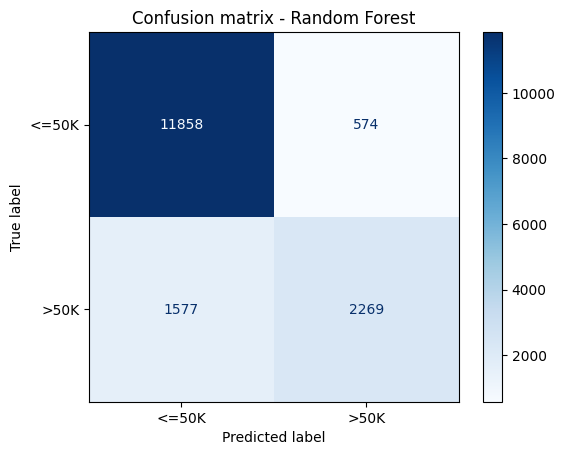

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.92     12432
        >50K       0.80      0.59      0.68      3846

    accuracy                           0.87     16278
   macro avg       0.84      0.77      0.80     16278
weighted avg       0.86      0.87      0.86     16278



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_model = models["Random Forest"]
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test,
                                      display_labels=["<=50K", ">50K"], cmap="Blues")
plt.title("Confusion matrix - Random Forest")
plt.show()

y_pred_rf = best_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=["<=50K", ">50K"]))

The confusion matrix of the Random Forest shows that it correctly finds 11858 people earning 50K or less and 2269 people earning more than 50K. It makes 574 false positives (predicts more than 50K but the person earns 50K or less) and 1577 false negatives (misses people earning more than 50K).

The classification report shows the results for both classes. For people earning 50K or less, the model finds 95% of them (recall 0.95) and is right 88% of the time when it predicts "50K or less" (precision 0.88). For people earning more than 50K, it is right 80% of the time when it predicts "more than 50K" (precision 0.80), but it finds only 59% of them (recall 0.59). So the model is very good at recognizing people earning 50K or less, but it misses a lot of people earning more than 50K, because it saw many more examples of them during training.

In [ ]:
rf_balanced = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42,
                                     n_jobs=-1, class_weight="balanced")
rf_balanced.fit(X_train, y_train)
y_pred_bal = rf_balanced.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred_bal), 3))
print("Precision:", round(precision_score(y_test, y_pred_bal), 3))
print("Recall   :", round(recall_score(y_test, y_pred_bal), 3))
print("F1       :", round(f1_score(y_test, y_pred_bal), 3))

Accuracy : 0.828
Precision: 0.596
Recall   : 0.843
F1       : 0.699


To deal with the imbalance, we trained the Random Forest again with class_weight="balanced", which gives more importance to the >50K class during training. The recall goes up from 0.59 to 0.84 (the model finds many more people earning >50K) and the F1-score goes up a bit (0.678 to 0.699), but the precision goes down from 0.80 to 0.60 and the accuracy from 0.868 to 0.828. It's a trade-off: for a marketing campaign that wants to reach as many people earning >50K as possible, the balanced model is better; for a bank that wants to avoid giving credit to the wrong people, the normal model is better.

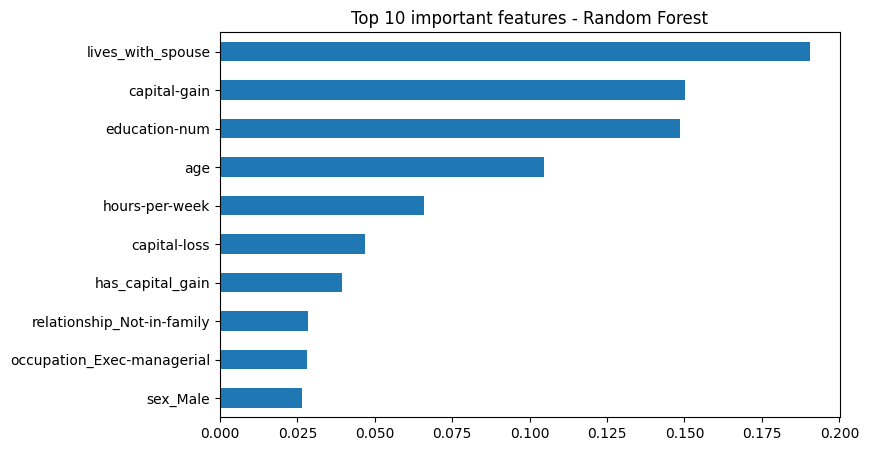

In [ ]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
importances.sort_values().tail(10).plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 important features - Random Forest")
plt.show()

The most important features for the Random Forest are lives_with_spouse, capital-gain, education-num, age and hours-per-week. This matches what we found in the exploration. lives_with_spouse, the column we created in the feature engineering, is the most important feature of all, which shows our feature engineering was useful.

## 7. Conclusion

In this lab we prepared the Adult dataset: we found hidden missing values ("?"), duplicates, impossible rows (women labeled "Husband"), and special values (99999). We justified each choice: "Unknown" instead of deleting the missing values because they were not random, keeping the outliers because they were real people, log transformation for skewed columns, one-hot encoding for categories without order, and new features based on the exploration.

With K-Means we found 4 groups of people with very different income levels (from 6% to 63% earning >50K), even without using the income. For the classification, we compared 5 models on the official test set, and Random Forest gave the best results (accuracy 0.868, ROC-AUC 0.919), better than the old results reported in adult.names. The main limit is the low recall on the >50K class because of the imbalance, which we improved with class_weight="balanced", at the cost of precision.

Finally, the data is from 1994 and contains sensitive features like sex and race. A model trained on it could reproduce old inequalities, so it should be used carefully.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')